In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

class ControlledNetworkReplicator:
    def __init__(self, G, num_modes, global_B, global_M, gamma=0.1, rho=0.01, neighbor_mode='auto'):
        """
        Simulator for Multi-Population Replicator Dynamics with external policy control (g).
        Control vector 'g' is added directly to the cost vector.
        """
        self.G = G
        self.num_modes = num_modes
        self.global_B = np.asarray(global_B, dtype=float)
        self.global_M = np.asarray(global_M, dtype=float)
        self.gamma = gamma
        self.rho = rho
        self.neighbor_mode = neighbor_mode
        self.states = {}
        self._initialize_network_properties()
        self.base_cost = np.zeros((len(G.nodes()), num_modes), dtype=float)

    def _initialize_network_properties(self):
        for node in self.G.nodes():
            if 'modal_share' in self.G.nodes[node]:
                self.states[node] = np.array(self.G.nodes[node]['modal_share'], dtype=float)
            else:
                self.states[node] = np.ones(self.num_modes) / self.num_modes
            if 'population' not in self.G.nodes[node]:
                self.G.nodes[node]['population'] = 1000.0

    def _get_spillover_neighbors(self, node):
        if self.neighbor_mode == 'auto':
            return list(self.G.successors(node)) if self.G.is_directed() else list(self.G.neighbors(node))
        return list(self.G.neighbors(node))

    def compute_controlled_costs(self, g_dict):
        """
        Computes costs including the external control vector g:
        C_i_new = C_i*(1 + g_i) for each node i.
        
        g_dict: dictionary mapping node -> np.array of shape (num_modes,)
        """
        costs = {}
        for node in self.G.nodes():
            B_i = np.array(self.G.nodes[node].get('B', self.global_B))
            M_i = np.array(self.G.nodes[node].get('M', self.global_M))
            x_i = self.states[node]
            
            # Base network cost (local + spillover)
            local_cost = B_i + (M_i @ x_i)
            spillover = np.zeros(self.num_modes)
            neighbors = self._get_spillover_neighbors(node)
            for nbr in neighbors:
                weight = self.G.edges[node, nbr].get('weight', 1.0) if self.G.has_edge(node, nbr) else 1.0
                M_j = np.array(self.G.nodes[nbr].get('M', self.global_M))
                x_j = self.states[nbr]
                spillover += weight * (M_j @ x_j)
            
            self.base_cost[node] = local_cost + self.gamma * spillover
                        
            # Apply policy control g for this node (default to 0 if not provided)
            g_i = g_dict.get(node, np.zeros(self.num_modes))
            
            # Policy intervention alters the perceived cost
            costs[node] = self.base_cost[node] * (1 + g_i)
            
        return costs

    def step(self, g_dict):
        """
        Advances the network state by one step using the controlled costs.
        """
        controlled_costs = self.compute_controlled_costs(g_dict)
        next_states = {}
        
        for node in self.G.nodes():
            x = self.states[node]
            C = controlled_costs[node]
            mu = np.dot(x, C)
            
            dx = self.rho * x * (mu - C)
            new_x = x + dx
            new_x = np.clip(new_x, 1e-7, None)
            new_x /= np.sum(new_x)
            
            next_states[node] = new_x
            
        self.states = next_states

    def get_system_fitness(self, current_costs):
        """Calculates population-weighted average system fitness (-mean_cost)."""
        total_pop = 0.0
        weighted_fitness_sum = 0.0
        for node in self.G.nodes():
            pop = self.G.nodes[node]['population']
            mu_node = np.dot(self.states[node], current_costs[node])
            weighted_fitness_sum += pop * (-mu_node)
            total_pop += pop
        return weighted_fitness_sum / total_pop if total_pop > 0 else 0.0

In [2]:
# =============================================================================
# RANDOM POLICY TESTER IMPLEMENTATION
# =============================================================================
def test_random_policy(env, steps=50, lambda_penalty=0.1, seed=42):
    """
    Simulates a Random Policy where at each step, a random pressure vector 'g'
    is applied to each node, and the RL Reward is calculated and tracked.
    """
    np.random.seed(seed)
    reward_history = []
    fitness_history = []
    action_cost_history = []
    
    print(f"Starting Random Policy Test for {steps} steps...")
    
    for t in range(steps):
        # 1. Generate random actions (g) for each node
        # Let's say g can vary between -5.0 (heavy subsidy) and +5.0 (heavy tax)
        g_dict = {}
        total_action_norm = 0.0
        
        for node in env.G.nodes():
            # Random control vector for the 3 modes
            g_node = np.random.uniform(-0.1, 0.1, env.num_modes)
            g_dict[node] = g_node
            
            # Track the magnitude of the action (L2 norm squared) for penalty
            total_action_norm += np.sum(g_node**2)
            
        # 2. Compute current costs BEFORE the dynamics step to evaluate current state reward
        # We use the actions selected for this step
        # current_costs = env.compute_controlled_costs(g_dict)

        # 3. Advance environment using the action
        env.step(g_dict)
        
        # 4. Calculate Reward components
        system_fitness = env.get_system_fitness(env.base_cost)  # Use the last computed base cost for fitness evaluation
        mean_action_penalty = total_action_norm / len(env.G.nodes())
        
        # RL Reward Formula: Reward = Fitness - lambda * Action_Penalty
        reward = system_fitness - (lambda_penalty * mean_action_penalty)
        
        # Save metrics
        reward_history.append(reward)
        fitness_history.append(system_fitness)
        action_cost_history.append(mean_action_penalty)
        
        
    print("Test completed.")
    return reward_history, fitness_history, action_cost_history

Starting Random Policy Test for 1000 steps...
Test completed.


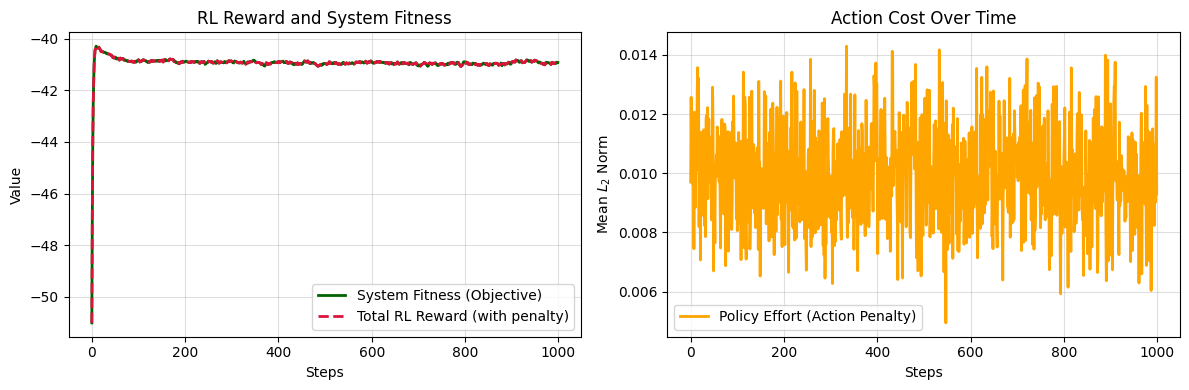

In [3]:
# =============================================================================
# EXECUTION
# =============================================================================
# Setup standard 3-mode scenario
global_B = np.array([20.0, 35.0, 25.0]) 
global_M = np.array([
    [45.0, 10.0,  5.0],
    [15.0, 20.0,  0.0],
    [ 5.0,  0.0, 15.0]
])

# Generate a sample network (10 nodes)
G = nx.erdos_renyi_graph(n=10, p=0.3, seed=42)
for node in G.nodes():
    G.nodes[node]['population'] = 1000.0
    G.nodes[node]['modal_share'] = [0.6, 0.2, 0.2] # Initial state
    
# Initialize Environment
env = ControlledNetworkReplicator(G, num_modes=3, global_B=global_B, global_M=global_M, gamma=0.1, rho=0.02)

# Run Random Policy Test
steps = 1000
rewards, fitness, act_costs = test_random_policy(env, steps=steps, lambda_penalty=0.0)

# Plot RL Metrics
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(fitness, label='System Fitness (Objective)', color='darkgreen', linewidth=2)
plt.plot(rewards, label='Total RL Reward (with penalty)', color='crimson', linestyle='--', linewidth=2)
plt.title('RL Reward and System Fitness')
plt.xlabel('Steps')
plt.ylabel('Value')
plt.legend()
plt.grid(True, alpha=0.4)

plt.subplot(1, 2, 2)
plt.plot(act_costs, color='orange', linewidth=2, label='Policy Effort (Action Penalty)')
plt.title('Action Cost Over Time')
plt.xlabel('Steps')
plt.ylabel('Mean $L_2$ Norm')
plt.legend()
plt.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

In [4]:
# =============================================================================
# HEURISTIC PROPORTIONAL POLICY (BENCHMARK)
# =============================================================================
def compute_heuristic_policy(env, alpha=0.6):
    """
    Heuristic Policy based on Modal Share Deviation (Congestion Pricing).
    Tax over-utilized modes (g > 0) and subsidize under-utilized modes (g < 0).
    
    Parameters:
    -----------
    env : ControlledNetworkReplicator instance
    alpha : float
        Sensitivity factor. Higher alpha means more aggressive taxes/subsidies.
    """
    g_dict = {}
    uniform_share = 1.0 / env.num_modes
    
    for node in env.G.nodes():
        x_i = env.states[node]
        
        # Calculate deviation from the uniform distribution
        # Positive deviation -> Over-utilized -> Tax applied
        # Negative deviation -> Under-utilized -> Subsidy applied
        deviation = x_i - uniform_share
        
        # Scale by alpha to get the control input g
        g_node = alpha * deviation
        
        # Clip strictly between [-0.5, 0.5] to ensure safety and realistic bounds
        g_node = np.clip(g_node, -0.5, 0.5)
        
        g_dict[node] = g_node
        
    return g_dict


def test_heuristic_policy(env, steps=50, alpha_policy=0.6, lambda_penalty=0.1):
    """
    Simulates the system under the Heuristic Policy and tracks RL metrics.
    """
    reward_history = []
    fitness_history = []
    action_cost_history = []
    
    print(f"Starting Heplicator Heuristic Policy Test ({steps} steps, alpha={alpha_policy})...")
    
    for t in range(steps):
        # 1. Compute smart actions based on current network state
        g_dict = compute_heuristic_policy(env, alpha=alpha_policy)
        
        # 2. Track action magnitude (L2 norm) for the RL penalty
        total_action_norm = 0.0
        for node in env.G.nodes():
            total_action_norm += np.sum(g_dict[node]**2)
            
        # 3. Compute costs with the active policy to evaluate reward
        # current_costs = env.compute_controlled_costs(g_dict)
        
        # 5. Step the simulation forward
        env.step(g_dict)

        # 4. Calculate RL Reward components
        system_fitness = env.get_system_fitness(env.base_cost)  # Use the last computed base cost for fitness evaluation
        mean_action_penalty = total_action_norm / len(env.G.nodes())
        
        # Reward = Fitness - lambda * Action_Cost
        reward = system_fitness - (lambda_penalty * mean_action_penalty)
        
        # Save metrics
        reward_history.append(reward)
        fitness_history.append(system_fitness)
        action_cost_history.append(mean_action_penalty)        
        
    print("Heuristic benchmark test completed.")
    return reward_history, fitness_history, action_cost_history


Running Heuristic Policy Test with alpha=0.0...
Starting Heplicator Heuristic Policy Test (1000 steps, alpha=0.0)...
Heuristic benchmark test completed.
Alpha=0.0: Final System Fitness=-40.9133, Final RL Reward=-40.9133, Total rewards=-40905.0459, Total Action Cost=0.0000

Running Heuristic Policy Test with alpha=0.2...
Starting Heplicator Heuristic Policy Test (1000 steps, alpha=0.2)...
Heuristic benchmark test completed.
Alpha=0.2: Final System Fitness=-40.4340, Final RL Reward=-40.4340, Total rewards=-40480.4260, Total Action Cost=5.6521

Running Heuristic Policy Test with alpha=0.4...
Starting Heplicator Heuristic Policy Test (1000 steps, alpha=0.4)...
Heuristic benchmark test completed.
Alpha=0.4: Final System Fitness=-40.4666, Final RL Reward=-40.4666, Total rewards=-40468.3408, Total Action Cost=14.0127

Running Heuristic Policy Test with alpha=0.6...
Starting Heplicator Heuristic Policy Test (1000 steps, alpha=0.6)...
Heuristic benchmark test completed.
Alpha=0.6: Final System

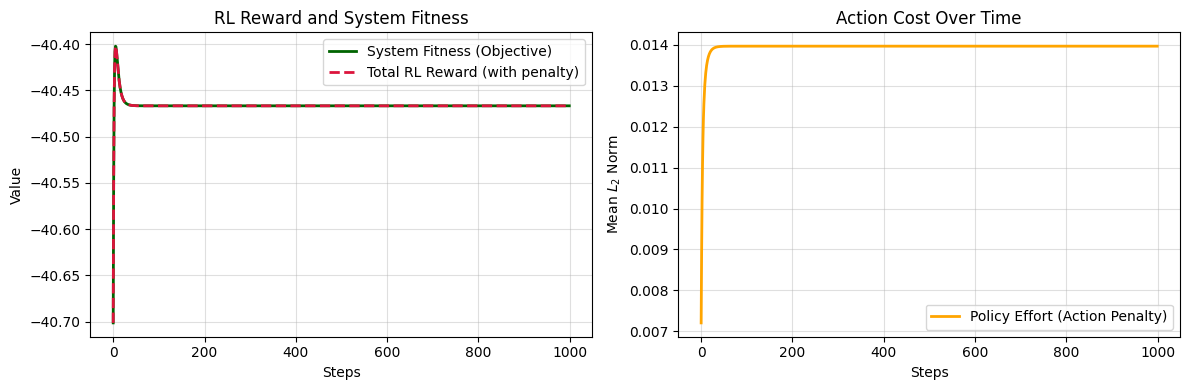

In [5]:
# Initialize Environment
env = ControlledNetworkReplicator(G, num_modes=3, global_B=global_B, global_M=global_M, gamma=0.1, rho=0.02)

# Run Random Policy Test
steps = 1000
for alpha in [0.0, 0.2, 0.4, 0.6, 0.8]:
    print(f"\nRunning Heuristic Policy Test with alpha={alpha}...")
    rewards, fitness, act_costs = test_heuristic_policy(env, steps=steps, alpha_policy=alpha, lambda_penalty=0.0)

    print(f"Alpha={alpha}: Final System Fitness={fitness[-1]:.4f}, Final RL Reward={rewards[-1]:.4f}, Total rewards={np.sum(rewards):.4f}, Total Action Cost={np.sum(act_costs):.4f}")
    
rewards, fitness, act_costs = test_heuristic_policy(env, steps=steps, alpha_policy=0.4, lambda_penalty=0.0)

# Plot RL Metrics
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(fitness, label='System Fitness (Objective)', color='darkgreen', linewidth=2)
plt.plot(rewards, label='Total RL Reward (with penalty)', color='crimson', linestyle='--', linewidth=2)
plt.title('RL Reward and System Fitness')
plt.xlabel('Steps')
plt.ylabel('Value')
plt.legend()
plt.grid(True, alpha=0.4)

plt.subplot(1, 2, 2)
plt.plot(act_costs, color='orange', linewidth=2, label='Policy Effort (Action Penalty)')
plt.title('Action Cost Over Time')
plt.xlabel('Steps')
plt.ylabel('Mean $L_2$ Norm')
plt.legend()
plt.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

# RL control

In [6]:
import numpy as np
import networkx as nx
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env
import matplotlib.pyplot as plt
import torch

In [7]:
# =============================================================================
# WRAPPER GYMNASIUM PER L'AMBIENTE RL
# =============================================================================
class CityTransportEnv(gym.Env):
    """Custom Environment that follows gymnasium interface"""
    metadata = {'render_modes': ['console']}

    def __init__(self, sim, max_steps=100, lambda_penalty=0.01):
        super(CityTransportEnv, self).__init__()
        
        self.sim = sim
        self.max_steps = max_steps
        self.lambda_penalty = lambda_penalty
        self.current_step = 0
        
        self.num_nodes = len(self.sim.G.nodes())
        self.num_modes = self.sim.num_modes
        
        # ---------------------------------------------------------------------
        # ACTION SPACE: Vettore 1D continuo tra -0.5 e 0.5
        # Dimensione: num_nodes * num_modes
        # ---------------------------------------------------------------------
        self.action_space = spaces.Box(
            low=-0.5, 
            high=0.5, 
            shape=(self.num_nodes * self.num_modes,), 
            dtype=np.float32
        )
        
        # ---------------------------------------------------------------------
        # OBSERVATION SPACE: Vettore 1D
        # Stato richiesto: x_locale (num_modes) + x_medio_vicini (num_modes)
        # Dimensione: num_nodes * (num_modes * 2)
        # ---------------------------------------------------------------------
        obs_dim_per_node = self.num_modes * 2
        self.observation_space = spaces.Box(
            low=0.0, 
            high=1.0, # Le quote modali sono limitate tra 0 e 1
            shape=(self.num_nodes * obs_dim_per_node,), 
            dtype=np.float32
        )
        
        # Salviamo lo stato iniziale per poter resettare l'episodio
        self.initial_states = {n: self.sim.states[n].copy() for n in self.sim.G.nodes()}

    def _get_obs(self):
        """
        COSTRUISCE LO STATO (OBSERVATION). 
        Modifica questa funzione se vuoi aggiungere informazioni (es. trafffico totale, pesi, centrality).
        """
        obs = []
        for node in self.sim.G.nodes():
            # 1. Stato locale (le quote x1, x2, x3 attuali sul nodo)
            x_local = self.sim.states[node]
            
            # 2. Stato medio dei vicini
            neighbors = list(self.sim.G.neighbors(node))
            if len(neighbors) > 0:
                x_neighbors = np.array([self.sim.states[nbr] for nbr in neighbors])
                x_neighbors_mean = np.mean(x_neighbors, axis=0)
            else:
                x_neighbors_mean = np.zeros(self.num_modes) # Caso limite: nodo isolato
                
            obs.extend(x_local)
            obs.extend(x_neighbors_mean)
            
        return np.array(obs, dtype=np.float32)

    def _get_true_fitness(self):
        """
        Calcola la fitness reale (negativo dei costi di congestione veri), 
        IGNORANDO i g della policy, che servono solo a spostare le persone.
        """
        empty_g = {node: np.zeros(self.num_modes) for node in self.sim.G.nodes()}
        true_costs = self.sim.compute_controlled_costs(empty_g) # Usa g=0 per calcolare i costi fisici
        return self.sim.get_system_fitness(true_costs)

    def reset(self, seed=None, options=None):
        """Resetta l'ambiente all'inizio di ogni episodio di RL."""
        super().reset(seed=seed)
        self.current_step = 0
        
        # Ripristina le quote modali iniziali nel simulatore
        for node in self.sim.G.nodes():
            self.sim.states[node] = self.initial_states[node].copy()
            
        return self._get_obs(), {}

    def step(self, action):
        """Esegue uno step della dinamica replicatrice applicando l'azione RL."""
        # 1. Decodifica l'azione PPO 1D in un dizionario g_dict
        g_dict = {}
        idx = 0
        for node in self.sim.G.nodes():
            g_dict[node] = action[idx : idx + self.num_modes]
            idx += self.num_modes
            
        # 2. Applica la pressione g e fai evolvere il sistema di 1 step
        self.sim.step(g_dict)
        self.current_step += 1
        
        # 3. Calcola il REWARD
        true_fitness = self._get_true_fitness()
        action_penalty = np.mean(action**2) # Penalizza interventi troppo pesanti (L2 norm)
        
        reward = true_fitness - (self.lambda_penalty * action_penalty)
        
        # 4. Controlla la terminazione dell'episodio
        terminated = False
        truncated = self.current_step >= self.max_steps
        
        info = {
            'true_fitness': true_fitness,
            'action_penalty': action_penalty
        }
        
        return self._get_obs(), float(reward), terminated, truncated, info

In [8]:
# =============================================================================
# TRAINING E TESTING SCRIPT CON PPO
# =============================================================================
# NOTA: Assicurati di avere la classe `ControlledNetworkReplicator` definita in questo script 
# o importata (come l'abbiamo scritta nei turni precedenti).

# 1. SETUP DEL MODELLO BASE (Network e Simulatore)
global_B = np.array([20.0, 35.0, 25.0]) 
global_M = np.array([
    [45.0, 10.0,  5.0],
    [15.0, 20.0,  0.0],
    [ 5.0,  0.0, 15.0]
])

# Rete di test (Erdos-Renyi)
G = nx.erdos_renyi_graph(n=10, p=0.3, seed=42)
for node in G.nodes():
    G.nodes[node]['population'] = 1000.0
    G.nodes[node]['modal_share'] = [0.6, 0.2, 0.2] # Tutti partono in auto

# Inizializza il simulatore (ATTENZIONE: usa la versione con costo moltiplicativo)
sim = ControlledNetworkReplicator(G, num_modes=3, global_B=global_B, global_M=global_M, gamma=0.1, rho=0.02)

In [19]:
# 2. INIZIALIZZA L'AMBIENTE GYM
env = CityTransportEnv(sim, max_steps=50, lambda_penalty=1.0)

# Verifica che l'ambiente sia conforme agli standard Gym (MOLTO IMPORTANTE)
check_env(env, warn=True)
print("L'ambiente è valido e compatibile con Stable Baselines3!")

L'ambiente è valido e compatibile con Stable Baselines3!


In [10]:
# 3. SETUP DEL MODELLO PPO

# Definiamo i parametri della rete neurale
policy_kwargs = dict(
    # Scegliamo la funzione di attivazione (es. nn.ReLU oppure nn.Tanh)
    # Importante: stable_baselines3 accetta le classi di torch.nn direttamente
    activation_fn=torch.nn.ReLU, 
    
    # Definiamo l'architettura degli strati nascosti (Hidden Layers)
    net_arch=dict(
        pi=[128, 128],  # Architettura dell'Attore (Policy -> 'pi')
        vf=[128, 128]   # Architettura del Critico (Value Function -> 'vf')
    )
)

# Passiamo il dizionario al costruttore PPO
model = PPO(
    "MlpPolicy", 
    env, 
    verbose=1, 
    learning_rate=0.0001, 
    n_steps=1000,
    policy_kwargs=policy_kwargs  # <--- Applichiamo le modifiche qui!
)

print("Modello PPO inizializzato con successo. Inizio addestramento...")
# Addestra la rete (metti es. 50000 per un training vero, qui teniamo basso per test)
model.learn(total_timesteps=100000)
print("--- Training Completato ---\n")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/home/alepitt/phd/network_congestion_game/.venv/lib/python3.14/site-packages/stable_baselines3/ppo/ppo.py:155: UserWarning: You have specified a mini-batch size of 64, but because the `RolloutBuffer` is of size `n_steps * n_envs = 1000`, after every 15 untruncated mini-batches, there will be a truncated mini-batch of size 40
We recommend using a `batch_size` that is a factor of `n_steps * n_envs`.
Info: (n_steps=1000 and n_envs=1)
  warnings.warn(


Modello PPO inizializzato con successo. Inizio addestramento...
----------------------------------
| rollout/           |           |
|    ep_len_mean     | 50        |
|    ep_rew_mean     | -2.13e+03 |
| time/              |           |
|    fps             | 558       |
|    iterations      | 1         |
|    time_elapsed    | 1         |
|    total_timesteps | 1000      |
----------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 50          |
|    ep_rew_mean          | -2.13e+03   |
| time/                   |             |
|    fps                  | 426         |
|    iterations           | 2           |
|    time_elapsed         | 4           |
|    total_timesteps      | 2000        |
| train/                  |             |
|    approx_kl            | 0.008637819 |
|    clip_fraction        | 0.0621      |
|    clip_range           | 0.2         |
|    entropy_loss         | -42.6       

--- Inizio Test Policy Ottimizzata ---


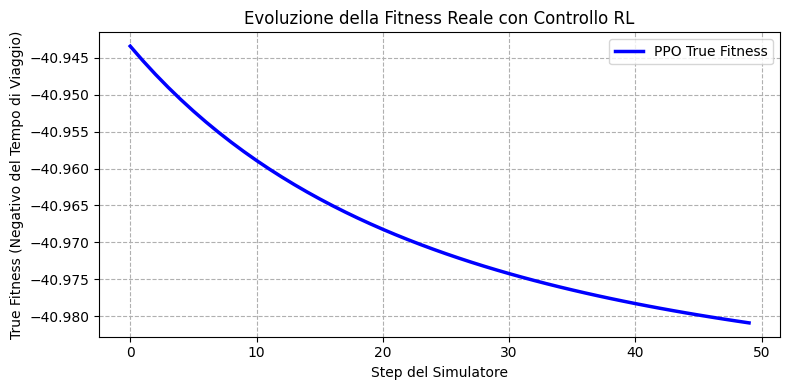

In [20]:
# 4. TESTIAMO LA POLICY ADDESTRATA
print("--- Inizio Test Policy Ottimizzata ---")
obs, info = env.reset()
fitness_history = []

for i in range(50):
    # Il modello PPO sceglie in modo deterministico (deterministic=True per test)
    action, _states = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = env.step(action)
    
    fitness_history.append(info['true_fitness'])
    
    if terminated or truncated:
        break

# 5. PLOT DEI RISULTATI
plt.figure(figsize=(8, 4))
plt.plot(fitness_history, color='blue', linewidth=2.5, label='PPO True Fitness')
plt.title('Evoluzione della Fitness Reale con Controllo RL')
plt.xlabel('Step del Simulatore')
plt.ylabel('True Fitness (Negativo del Tempo di Viaggio)')
plt.grid(True, linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()